# Annual Giving Strategy: Segment Analysis, Channel ROI and New Donor Retention
Exploring a synthetic annual giving dataset (FY22–FY26) to answer three questions a fundraising team faces when deciding where to focus its budget and staff time. **Part 1** looks at who the current donors are, their giving level, and the channels they chose to give through. **Part 2** focuses on ROI, comparing what each channel costs against what it raises. **Part 3** looks at new donors: since most first-time donors never give again, where do new donors come from, and which ones make a second gift? 

The data was generated to reflect a smaller organization's annual giving program, with response rates, costs, and retention modeled on published fundraising benchmarks (see the benchmark check below and the data README for details). All queries use standard SQL compatible with MySQL 8.0+ and run here in DuckDB. The notebook format makes code and corresponding notes easier to read.

## Key findings

All figures cover FY22–FY26 combined unless otherwise noted.

**Part 1: Who gives**
- **Current donors and the house file carry the program.** Appeals to people already in the database raised 68% of solicited revenue, and current donors responded to mail far more often than lapsed or never donors (10.5–16.6% per appeal vs. 2.9–4.1% and 0.7%).
- **Personal outreach to top donors works, as expected.** Just 46 donors produced 10% of solicited revenue, with an average gift of $712. These are already the program's best donors, so the results reflect who is asked as much as how.

**Part 2: What each channel costs**
- **Direct mail raises the most, at a lower return per dollar.** Over 5 years, direct mail returned $2.79 per $1 spent vs. $4.82-$7.27 for the other channels, but it raised far more money than all of them combined.
- **The acquisition mailing is what makes direct mail look expensive.** House file mail cost about $0.19–$0.22 to raise $1, while the acquisition mailing cost about $0.98–$1.17, roughly breaking even in its first year.

**Part 3: New donor retention**
- **New donors arrive through many doors.** About 445–465 new donors join each year, mostly through the acquisition mailing (164–197 a year) and unsolicited gifts (193–227 a year), many of them tribute or personal fundraiser gifts.
- **Most new donors never make a second gift.** Only 19% gave again by the end of the following fiscal year (24% excluding tribute and personal fundraiser donors, who almost never return at 4%). Acquisition, standard unsolicited, and social media donors all return at about 22–23%.
- **Second gifts come late.** Very few new donors give again within their first 12 months; most second gifts arrive 12–18 months after the first, with the next year's fall and year-end appeals. For acquisition donors, only 2% had given again by 12 months, compared with 16% by 18 months.
- **The second gift is what makes acquisition pay off.** Each acquisition mailing roughly breaks even in its first year, and every cohort from FY22–FY25 has already covered its cost through later gifts. That makes the first year after a donor's first gift the biggest opportunity.


## Setup

Imports the libraries and loads each CSV into DuckDB as its own table. Requires `duckdb`, `pandas`, and `matplotlib` (install DuckDB with `pip install duckdb` if needed).

In [1]:
import duckdb
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch


In [2]:
con = duckdb.connect()

tables = ["donors", "appeals", "appeal_segments", "solicitations",
          "gifts", "donor_fy_summary", "benchmark_check"]

for t in tables:
    con.execute(f"""
        CREATE OR REPLACE TABLE {t} AS
        SELECT * FROM read_csv_auto('data/{t}.csv')
    """)

con.sql("SHOW TABLES")

┌──────────────────┐
│       name       │
│     varchar      │
├──────────────────┤
│ appeal_segments  │
│ appeals          │
│ benchmark_check  │
│ donor_fy_summary │
│ donors           │
│ gifts            │
│ solicitations    │
└──────────────────┘

## Data validation

Before any analysis, these checks confirm that the gifts table loaded correctly, the data types are correct, null values (if any) are identified, and gift dates line up with the fiscal years. Because this is a synthetic dataset, this process is easy but it is important to check with real data from a CRM export. 

In [3]:
con.sql("""
    WITH missing AS (
        SELECT 'gift_id'        AS column_name, COUNT(*) - COUNT(gift_id)        AS missing_values FROM gifts
        UNION ALL SELECT 'donor_id',       COUNT(*) - COUNT(donor_id)       FROM gifts
        UNION ALL SELECT 'gift_date',      COUNT(*) - COUNT(gift_date)      FROM gifts
        UNION ALL SELECT 'fiscal_year',    COUNT(*) - COUNT(fiscal_year)    FROM gifts
        UNION ALL SELECT 'amount',         COUNT(*) - COUNT(amount)         FROM gifts
        UNION ALL SELECT 'appeal_id',      COUNT(*) - COUNT(appeal_id)      FROM gifts
        UNION ALL SELECT 'segment_group',  COUNT(*) - COUNT(segment_group)  FROM gifts
        UNION ALL SELECT 'fund',           COUNT(*) - COUNT(fund)           FROM gifts
        UNION ALL SELECT 'gift_type',      COUNT(*) - COUNT(gift_type)      FROM gifts
    )
    SELECT
        c.column_name,
        c.data_type,
        m.missing_values
    FROM information_schema.columns c
    JOIN missing m ON m.column_name = c.column_name
    WHERE c.table_name = 'gifts'
    ORDER BY c.ordinal_position
""").df()

,column_name,data_type,missing_values
0,gift_id,VARCHAR,0
1,donor_id,VARCHAR,0
2,gift_date,DATE,0
3,fiscal_year,BIGINT,0
4,amount,DOUBLE,0
5,appeal_id,VARCHAR,0
6,segment_group,VARCHAR,0
7,fund,VARCHAR,0
8,gift_type,VARCHAR,0


In [4]:
con.sql("""
    SELECT
        fiscal_year,
        MIN(gift_date)       AS first_gift,
        MAX(gift_date)       AS last_gift,
        COUNT(*)             AS gifts,
        ROUND(SUM(amount))   AS revenue
    FROM gifts
    GROUP BY fiscal_year
    ORDER BY fiscal_year
""").df()

,fiscal_year,first_gift,last_gift,gifts,revenue
0,2022,2021-07-04,2022-06-30,1087,122502.0
1,2023,2022-07-01,2023-06-30,1042,121654.0
2,2024,2023-07-06,2024-06-30,1014,131310.0
3,2025,2024-07-02,2025-06-30,1026,147997.0
4,2026,2025-07-02,2026-06-30,998,132368.0


The query results show the first and last gift dates and totals for each FY to confirm that the gift data aligns with the fiscal years and gives quick gift and revenue totals for each to get a sense of the changes over the years.

### Benchmark check

Real donor data is confidential and can't be shared publicly, so this project uses a synthetic dataset I built to mirror a small nonprofit's annual giving program. Response rates, costs, and retention are modeled on published fundraising benchmarks and on my experience in fundraising operations. Because it's generated, the data is cleaner and more predictable than a real CRM export, so the focus here is on the analysis approach and the questions it answers rather than on the specific results. Retention and direct mail results land close to their benchmarks while email runs higher to reflect a smaller organization's more engaged list. The direct mail benchmarks are based on current and lapsed donors while the house file includes the mailings to never donors so the figures are a bit lower. A detailed list of the sources used for these benchmarks is included in the README file for this project. 


In [5]:
con.sql("""
    SELECT metric, simulated, benchmark, source
    FROM benchmark_check
""").df()

,metric,simulated,benchmark,source
0,"Direct mail response, existing donors (current...",9.3%,5% to 9%,"ANA 2024 Response Rate Report (house lists, al..."
1,"Cost to raise $1, direct mail to existing donors",$0.15,$0.20 to $0.25,"Greenfield, Fund-Raising: Evaluating and Manag..."
2,"Cost to raise $1, direct mail acquisition",$1.07,$1.00 to $1.50,"Greenfield, Fund-Raising: Evaluating and Manag..."
3,Email response rate (all segments),0.28%,0.05%,"M+R Benchmarks 2026, Email Messaging"
4,"Email revenue per 1,000 sent",$348,$54,"M+R Benchmarks 2026, Email Messaging"
5,Email addresses lost to bounces per year,3.3%,4%,"M+R Benchmarks 2026, Email Messaging"
6,"Donor retention, overall",40.4%,43.3%,"Fundraising Effectiveness Project, Q4 2025 Report"
7,"Donor retention, new donors",18.8%,18.9%,"Fundraising Effectiveness Project, Q4 2025 Report"
8,"Donor retention, repeat donors",59.8%,59.3%,"Fundraising Effectiveness Project, Q4 2025 Report"
9,"Retention, new tribute donors",3.8%,single digits,"Bloomerang, Memorial and Tribute Donors Can Be..."


## Part 1: Who gives, at what level, and through which channels

Looks at the whole program first: how solicitations, donors, and revenue split across channels. Direct mail is split into the house file (people already in the database) and the acquisition mailing (a rented list of people new to the organization) because they reach very different donors.

In [6]:
channel_scale = con.sql("""
    WITH asked AS (
        SELECT
            CASE WHEN a.channel = 'Direct Mail' AND s.segment_group = 'Acquisition (Rented List)'
                     THEN 'Mail: acquisition'
                 WHEN a.channel = 'Direct Mail' THEN 'Mail: house file'
                 ELSE a.channel END            AS channel_group,
            SUM(s.audience_size)              AS asks_sent
        FROM appeal_segments s
        JOIN appeals a ON a.appeal_id = s.appeal_id
        WHERE a.channel <> 'Unsolicited'
        GROUP BY CASE WHEN a.channel = 'Direct Mail' AND s.segment_group = 'Acquisition (Rented List)'
                          THEN 'Mail: acquisition'
                      WHEN a.channel = 'Direct Mail' THEN 'Mail: house file'
                      ELSE a.channel END
    ),
    gave AS (
        SELECT
            CASE WHEN a.channel = 'Direct Mail' AND g.segment_group = 'Acquisition (Rented List)'
                     THEN 'Mail: acquisition'
                 WHEN a.channel = 'Direct Mail' THEN 'Mail: house file'
                 ELSE a.channel END            AS channel_group,
            COUNT(DISTINCT g.donor_id)        AS unique_donors,
            COUNT(*)                          AS gifts,
            SUM(g.amount)                     AS revenue,
            MIN(g.amount)                     AS smallest_gift,
            MAX(g.amount)                     AS largest_gift
        FROM gifts g
        JOIN appeals a ON a.appeal_id = g.appeal_id
        WHERE a.channel <> 'Unsolicited'
        GROUP BY CASE WHEN a.channel = 'Direct Mail' AND g.segment_group = 'Acquisition (Rented List)'
                          THEN 'Mail: acquisition'
                      WHEN a.channel = 'Direct Mail' THEN 'Mail: house file'
                      ELSE a.channel END
    )
    SELECT
        g.channel_group,
        s.asks_sent,
        g.unique_donors,
        g.gifts,
        ROUND(g.revenue)                                      AS revenue,
        ROUND(100.0 * g.revenue / SUM(g.revenue) OVER (), 1)  AS pct_of_revenue,
        ROUND(g.revenue / g.gifts, 2)                         AS avg_gift,
        g.smallest_gift,
        g.largest_gift
    FROM gave g
    LEFT JOIN asked s ON s.channel_group = g.channel_group
    ORDER BY revenue DESC
""").df()

channel_scale

,channel_group,asks_sent,unique_donors,gifts,revenue,pct_of_revenue,avg_gift,smallest_gift,largest_gift
0,Mail: house file,35943.0,1081,2334,357549.0,68.0,153.19,5.0,1500.00
1,Mail: acquisition,90000.0,931,931,78465.0,14.9,84.28,5.0,1035.37
2,Personal Outreach,232.0,46,73,51997.0,9.9,712.29,225.0,2750.00
3,Email,59823.0,152,166,20841.0,4.0,125.55,5.0,1500.00
4,Social Media,NaN,245,246,16842.0,3.2,68.46,5.0,583.14


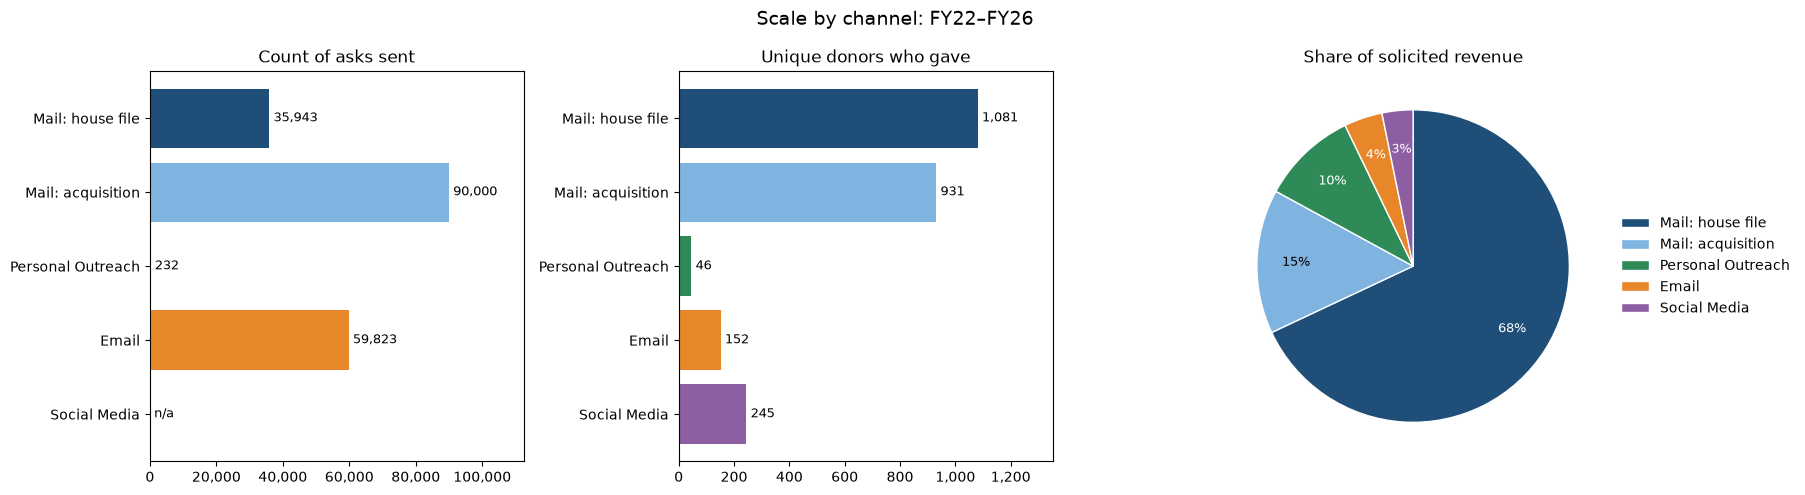

In [7]:
# One color per channel, used in all three panels
channel_colors = {
    "Mail: house file":  "#1f4e79",   # dark blue
    "Mail: acquisition": "#7fb3e0",   # light blue
    "Personal Outreach": "#2e8b57",   # green
    "Email":             "#e8862a",   # orange
    "Social Media":      "#8e5ea2",   # purple
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5),
                         gridspec_kw={"width_ratios": [1, 1, 1.1]})
scale = channel_scale.set_index("channel_group").iloc[::-1]   # largest at top

# Left and middle: bar charts
for ax, (column, title) in zip(axes[:2], [("asks_sent", "Count of asks sent"),
                                          ("unique_donors", "Unique donors who gave")]):
    values = scale[column].fillna(0)
    bars = ax.barh(values.index, values.values,
                   color=[channel_colors[c] for c in values.index])
    labels = ["n/a" if (column == "asks_sent" and v == 0) else f"{v:,.0f}" for v in values]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, values.max() * 1.25)
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")

# Right: pie chart of revenue share
revenue = channel_scale.set_index("channel_group")["revenue"]
wedges, texts, pct_labels = axes[2].pie(
    revenue, autopct="%1.0f%%", startangle=90, counterclock=False,
    pctdistance=0.75, wedgeprops=dict(edgecolor="white"),
    colors=[channel_colors[c] for c in revenue.index])
for label, color in zip(pct_labels, ["white", "black", "white", "white", "white"]):
    label.set_color(color)
    label.set_fontsize(9)
axes[2].legend(wedges, revenue.index, loc="center left",
               bbox_to_anchor=(1, 0.5), frameon=False)
axes[2].set_title("Share of solicited revenue")

fig.suptitle("Scale by channel: FY22–FY26", fontsize=14)
plt.tight_layout()
fig.savefig("images/channel_scale.png", dpi=150, bbox_inches="tight")
plt.show()

"Unique donors" means the number of different people who made a gift through that channel. The same person can appear in more than one channel - for example, if a donor gave through the direct mail appeal and then via email, they would be counted for both. But, if they gave twice via email, they would be counted just once for that channel.

As expected, personal outreach to the program's top donors is highly productive: only 46 donors gave this way, but they produced 10% of solicited revenue. Because these donors were already giving at the highest level, the rest of this analysis focuses on the much larger groups who give through mail, email, and social media. The bigger contrast is between the house file and acquisition: the acquisition mailing went to 90,000 people over five years, more than any other channel, but produced only 15% of solicited revenue, compared with 68% from the house file's 35,943 pieces.

### Who responds to direct mail

Breaks house file mail down by segment: how recently donors last gave and how much. (Acquisition names come from a rented list and have no solicitation rows, so this covers the file from the database only.)

In [8]:
mail_segments = con.sql("""
    SELECT
        s.segment_group,
        s.appeal_segment,
        COUNT(*)                                       AS solicited,
        COUNT(g.gift_id)                               AS gifts,
        ROUND(100.0 * COUNT(g.gift_id) / COUNT(*), 1)  AS response_rate_pct,
        ROUND(AVG(g.amount), 2)                        AS avg_gift,
        ROUND(SUM(g.amount))                           AS revenue
    FROM solicitations s
    LEFT JOIN gifts g
      ON g.donor_id  = s.donor_id
      AND g.appeal_id = s.appeal_id
    WHERE s.appeal_id LIKE '%-DM-%'
    GROUP BY s.segment_group, s.appeal_segment
    ORDER BY response_rate_pct DESC
""").df()

mail_segments

,segment_group,appeal_segment,solicited,gifts,response_rate_pct,avg_gift,revenue
0,Current Donors,Current - Last Gift $100-$499,5364,890,16.6,222.98,198455.0
1,Current Donors,"Current - Last Gift $500-$1,000",429,63,14.7,738.49,46525.0
2,Current Donors,Current - Last Gift Under $100,9488,997,10.5,56.99,56816.0
3,Lapsed Donors,Lapsed 1 Yr - Last Gift $100+,977,40,4.1,279.96,11198.0
4,Lapsed Donors,Lapsed 2-4 Yrs,5701,198,3.5,168.39,33341.0
5,Lapsed Donors,Lapsed 1 Yr - Last Gift Under $100,2274,65,2.9,59.85,3890.0
6,Never Donors,Never Donors,11710,81,0.7,90.42,7324.0


Each row represents one mail segment, showing how often it responded and how much it gave. 

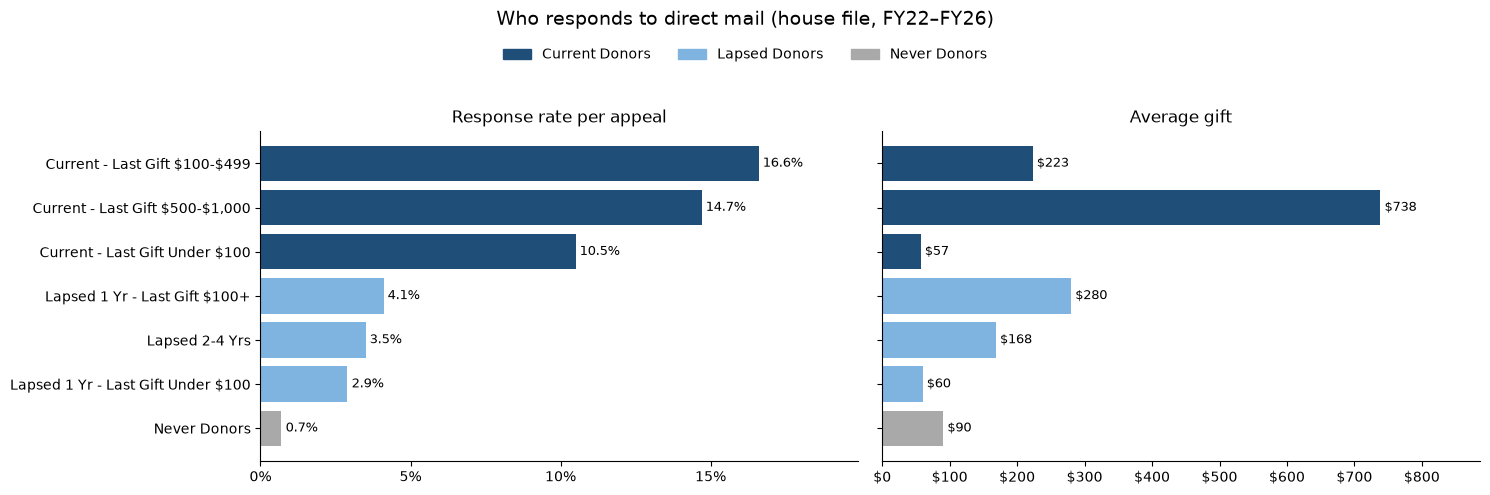

In [9]:

group_colors = {
    "Current Donors": "#1f4e79",   # dark blue
    "Lapsed Donors":  "#7fb3e0",   # light blue
    "Never Donors":   "#a9a9a9",   # gray
}
plot_data = mail_segments.iloc[::-1]   # highest response rate at the top
colors = [group_colors[g] for g in plot_data["segment_group"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Left: response rate
bars = axes[0].barh(plot_data["appeal_segment"], plot_data["response_rate_pct"], color=colors)
axes[0].bar_label(bars, labels=[f"{v:.1f}%" for v in plot_data["response_rate_pct"]],
                  padding=3, fontsize=9)
axes[0].set_title("Response rate per appeal")
axes[0].set_xlim(0, plot_data["response_rate_pct"].max() * 1.2)
axes[0].xaxis.set_major_formatter(lambda x, pos: f"{x:.0f}%")
axes[0].xaxis.set_major_locator(plt.MultipleLocator(5))

# Right: average gift
bars = axes[1].barh(plot_data["appeal_segment"], plot_data["avg_gift"], color=colors)
axes[1].bar_label(bars, labels=[f"${v:,.0f}" for v in plot_data["avg_gift"]],
                  padding=3, fontsize=9)
axes[1].set_title("Average gift")
axes[1].set_xlim(0, plot_data["avg_gift"].max() * 1.2)
axes[1].xaxis.set_major_formatter(lambda x, pos: f"${x:,.0f}")

for ax in axes:
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.legend(handles=[Patch(color=c, label=g) for g, c in group_colors.items()],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False)
axes[0].set_yticks(range(len(plot_data)),
                   labels=[s.replace("$", r"\$") for s in plot_data["appeal_segment"]])
fig.suptitle("Who responds to direct mail (house file, FY22–FY26)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.savefig("images/mail_segments.png", dpi=150, bbox_inches="tight")
plt.show()

The chart shows two different patterns.

**Response depends on how recently someone gave.** All three Current Donors segments respond far more often than anyone else (10.5–16.6% per appeal). Response drops sharply once donors lapse (2.9–4.1%), and Never Donors respond least of all (0.7%). This is the core pattern of annual giving: someone who gave recently is far more likely to give again, so keeping donors matters more than any single appeal.

**Gift size depends on how much someone gave last time.** Current donors whose last gift was $500–$1,000 averaged $738. Lapsed donors whose last gift was $100 or more still averaged $280 when they came back, far more than current donors whose last gift was under $100 ($57), even though they respond much less often. The few Never Donors who respond made first gifts averaging $90, slightly higher than the acquisition mailing's $84.

Part 2 turns from who gives to what it costs to reach them through each channel.

## Part 2: What each channel costs

Compares each channel's revenue with its cost, measured as revenue per $1 of total cost (out-of-pocket costs plus staff time) and as cost to raise $1. The first query compares all channels and the second splits direct mail to compare the house file with acquisition and the third ranks each mail segment by the revenue raised per $1 spent.

In [10]:
channel_roi = con.sql("""
    WITH seg_revenue AS (
        SELECT appeal_id, appeal_segment,
               COUNT(*)    AS gifts,
               SUM(amount) AS revenue
        FROM gifts
        GROUP BY appeal_id, appeal_segment
    )
    SELECT
        a.channel,
        SUM(s.audience_size)                                     AS asks_sent,
        COALESCE(SUM(r.gifts), 0)                                AS gifts,
        ROUND(COALESCE(SUM(r.revenue), 0))                       AS revenue,
        ROUND(SUM(s.hard_cost))                                  AS hard_cost,
        ROUND(SUM(s.staff_cost))                                 AS staff_cost,
        ROUND(SUM(s.total_cost))                                 AS total_cost,
        ROUND(SUM(s.hard_cost)  / NULLIF(SUM(r.revenue), 0), 3)  AS hard_cost_per_dollar,
        ROUND(SUM(s.staff_cost) / NULLIF(SUM(r.revenue), 0), 3)  AS staff_cost_per_dollar,
        ROUND(SUM(s.total_cost) / NULLIF(SUM(r.revenue), 0), 2)  AS cost_per_dollar,
        ROUND(SUM(r.revenue) / NULLIF(SUM(s.total_cost), 0), 2)  AS revenue_per_dollar
    FROM appeal_segments s
    JOIN appeals a ON a.appeal_id = s.appeal_id
    LEFT JOIN seg_revenue r
      ON r.appeal_id = s.appeal_id
     AND r.appeal_segment = s.appeal_segment
    WHERE a.channel <> 'Unsolicited'
    GROUP BY a.channel
    ORDER BY revenue DESC
""").df()

channel_roi

,channel,asks_sent,gifts,revenue,hard_cost,staff_cost,total_cost,hard_cost_per_dollar,staff_cost_per_dollar,cost_per_dollar,revenue_per_dollar
0,Direct Mail,125943.0,3265.0,436013.0,142745.0,13573.0,156317.0,0.327,0.031,0.36,2.79
1,Personal Outreach,232.0,73.0,51997.0,222.0,6926.0,7148.0,0.004,0.133,0.14,7.27
2,Email,59823.0,166.0,20841.0,598.0,3726.0,4324.0,0.029,0.179,0.21,4.82
3,Social Media,NaN,246.0,16842.0,0.0,2471.0,2471.0,0.000,0.147,0.15,6.82


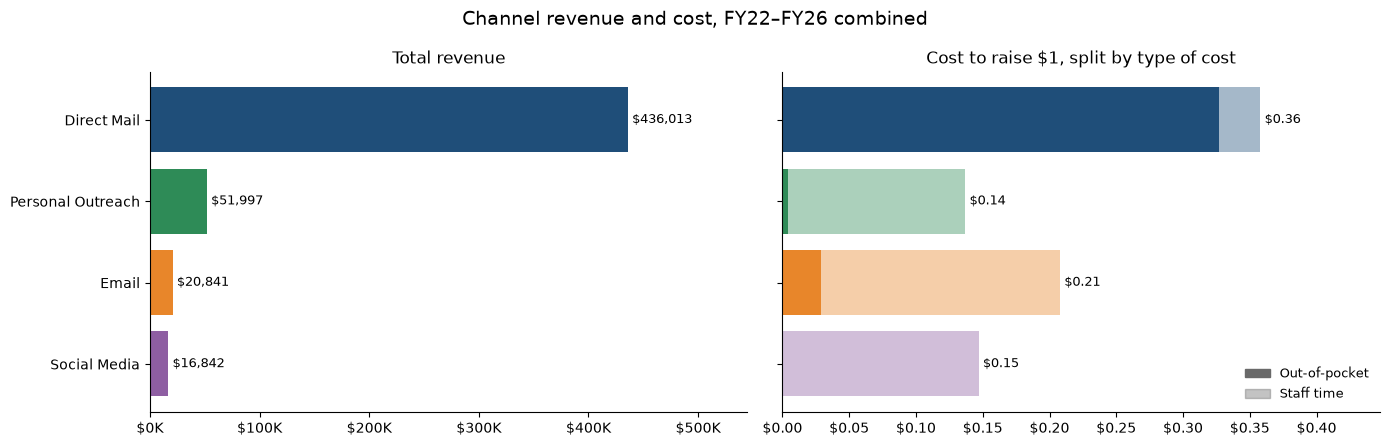

In [11]:
roi_colors = {
    "Direct Mail":       "#1f4e79",   # dark blue
    "Personal Outreach": "#2e8b57",   # green
    "Email":             "#e8862a",   # orange
    "Social Media":      "#8e5ea2",   # purple
}

plot_data = channel_roi.sort_values("revenue")   # largest at top
colors = [roi_colors[c] for c in plot_data["channel"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

# Left: total revenue
bars = axes[0].barh(plot_data["channel"], plot_data["revenue"], color=colors)
axes[0].bar_label(bars, labels=[f"${v:,.0f}" for v in plot_data["revenue"]],
                  padding=3, fontsize=9)
axes[0].set_title("Total revenue")
axes[0].set_xlim(0, plot_data["revenue"].max() * 1.25)
axes[0].xaxis.set_major_formatter(lambda x, pos: f"${x / 1000:,.0f}K")

# Right: cost to raise $1, stacked by type of cost
hard = plot_data["hard_cost_per_dollar"]
staff = plot_data["staff_cost_per_dollar"]
total = hard + staff

axes[1].barh(plot_data["channel"], hard, color=colors)                           # solid = out-of-pocket
bars = axes[1].barh(plot_data["channel"], staff, left=hard, color=colors, alpha=0.4)  # lighter = staff time
axes[1].bar_label(bars, labels=[f"${v:.2f}" for v in total], padding=3, fontsize=9)
axes[1].set_title("Cost to raise $1, split by type of cost")
axes[1].set_xlim(0, total.max() * 1.25)
axes[1].xaxis.set_major_formatter(lambda x, pos: f"${x:.2f}")
axes[1].legend(handles=[Patch(color="dimgray", label="Out-of-pocket"),
                        Patch(color="dimgray", alpha=0.4, label="Staff time")],
               frameon=False, fontsize=9, loc="lower right")

for ax in axes:
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("Channel revenue and cost, FY22–FY26 combined", fontsize=14)
plt.tight_layout()
fig.savefig("images/channel_cost.png", dpi=150, bbox_inches="tight")
plt.show()

Over five years, direct mail raised a total of $436,013, more than all other channels combined, but it returned the least per dollar: about $2.79 for each $1 spent, compared with $4.82 for email, $6.82 for social media, and $7.27 for personal outreach. The chart on the right shows why: direct mail’s cost is almost all out-of-pocket (printing, postage, etc.), while the cost of the other channels is almost entirely staff time. 

In [12]:
mail_house_vs_acq = con.sql("""
    WITH seg_revenue AS (
        SELECT appeal_id, appeal_segment,
               COUNT(*)    AS gifts,
               SUM(amount) AS revenue
        FROM gifts
        GROUP BY appeal_id, appeal_segment
    )
    SELECT
        a.fiscal_year,
        CASE WHEN s.segment_group = 'Acquisition (Rented List)'
             THEN 'Acquisition' ELSE 'House file' END              AS mail_list,
        SUM(s.audience_size)                                       AS pieces_mailed,
        COALESCE(SUM(r.gifts), 0)                                  AS gifts,
        ROUND(100.0 * COALESCE(SUM(r.gifts), 0)
              / SUM(s.audience_size), 2)                           AS response_rate_pct,
        ROUND(COALESCE(SUM(r.revenue), 0))                         AS revenue,
        ROUND(SUM(r.revenue) / NULLIF(SUM(r.gifts), 0), 2)         AS avg_gift,
        ROUND(SUM(s.total_cost))                                   AS total_cost,
        ROUND(SUM(s.total_cost) / NULLIF(SUM(r.revenue), 0), 2)    AS cost_per_dollar
    FROM appeal_segments s
    JOIN appeals a ON a.appeal_id = s.appeal_id
    LEFT JOIN seg_revenue r
      ON r.appeal_id = s.appeal_id
     AND r.appeal_segment = s.appeal_segment
    WHERE a.channel = 'Direct Mail'
    GROUP BY a.fiscal_year,
             CASE WHEN s.segment_group = 'Acquisition (Rented List)'
                  THEN 'Acquisition' ELSE 'House file' END
    ORDER BY a.fiscal_year, mail_list
""").df()

mail_house_vs_acq

,fiscal_year,mail_list,pieces_mailed,gifts,response_rate_pct,revenue,avg_gift,total_cost,cost_per_dollar
0,2022,Acquisition,18000.0,193.0,1.07,15943.0,82.60,17219.0,1.08
1,2022,House file,6892.0,516.0,7.49,65758.0,127.44,14227.0,0.22
2,2023,Acquisition,18000.0,181.0,1.01,14724.0,81.35,17177.0,1.17
3,2023,House file,7053.0,471.0,6.68,70267.0,149.19,14609.0,0.21
4,2024,Acquisition,18000.0,196.0,1.09,18143.0,92.57,17702.0,0.98
5,2024,House file,7307.0,461.0,6.31,70973.0,153.96,13878.0,0.20
6,2025,Acquisition,18000.0,164.0,0.91,13962.0,85.13,15852.0,1.14
7,2025,House file,7230.0,463.0,6.40,79507.0,171.72,14830.0,0.19
8,2026,Acquisition,18000.0,197.0,1.09,15693.0,79.66,15994.0,1.02
9,2026,House file,7461.0,423.0,5.67,71043.0,167.95,14827.0,0.21


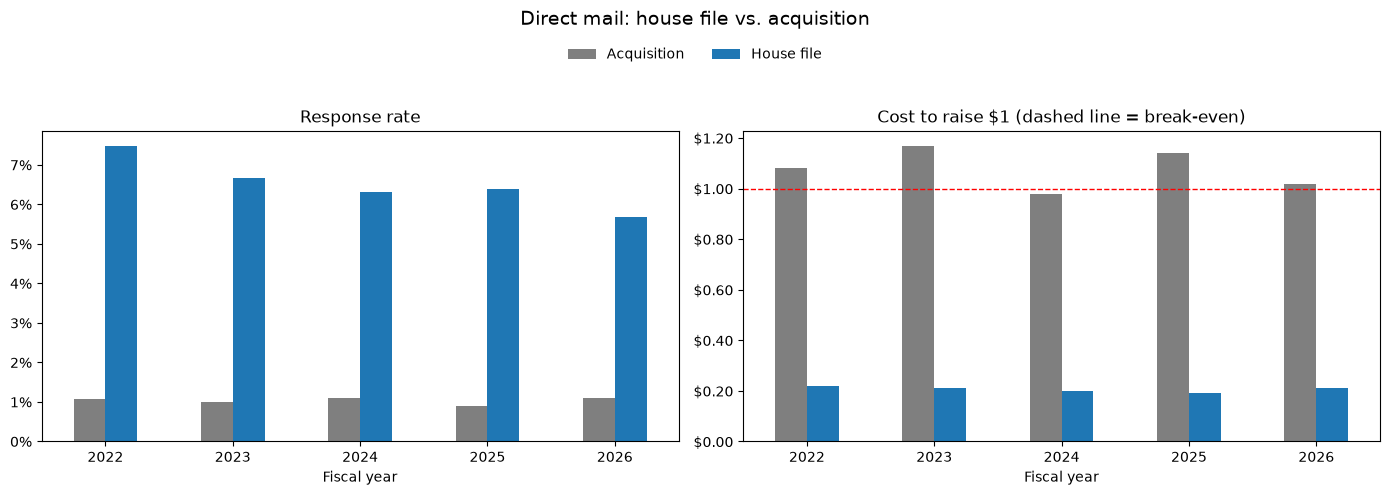

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

charts = [("response_rate_pct", "Response rate", lambda x, pos: f"{x:.0f}%"),
          ("cost_per_dollar", "Cost to raise $1 (dashed line = break-even)", lambda x, pos: f"${x:.2f}")]

for ax, (column, title, fmt) in zip(axes, charts):
    (mail_house_vs_acq
        .pivot(index="fiscal_year", columns="mail_list", values=column)
        .plot(kind="bar", ax=ax, legend=False, color=["tab:gray", "tab:blue"]))
    ax.set_title(title)
    ax.set_xlabel("Fiscal year")
    ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(fmt)

axes[1].axhline(1.0, color="red", linestyle="--", linewidth=1)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 0.93), frameon=False)

fig.suptitle("Direct mail: house file vs. acquisition", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.savefig("images/house_file_vs_acquisition.png", dpi=150, bbox_inches="tight")
plt.show()

Splitting direct mail in two changes the picture. The house file (people already in the database) has a response rate of about 5.7–7.5%, compared with about 1% for the acquisition mailing, and costs only about $0.19–$0.22 to raise $1, compared with $0.98–$1.17 for acquisition. In other words, appeals to existing donors are among the most efficient asks in the program, and the acquisition mailing is what pulls direct mail's overall return down.

The acquisition mailing roughly breaks even in its first year, so its value depends on whether the new donors it brings in give again. 

### Direct mail: revenue per $1 by segment

Compares revenue per $1 spent for each mail segment.

In [14]:
seg_rank = con.sql("""
    WITH seg_revenue AS (
        SELECT appeal_id, appeal_segment, SUM(amount) AS revenue
        FROM gifts
        GROUP BY appeal_id, appeal_segment
    ),
    seg_year AS (
        SELECT
            a.fiscal_year,
            s.appeal_segment,
            SUM(s.audience_size)               AS pieces_mailed,
            ROUND(COALESCE(SUM(r.revenue), 0)) AS revenue,
            ROUND(SUM(s.total_cost))           AS total_cost
        FROM appeal_segments s
        JOIN appeals a ON a.appeal_id = s.appeal_id
        LEFT JOIN seg_revenue r
          ON r.appeal_id = s.appeal_id
         AND r.appeal_segment = s.appeal_segment
        WHERE a.channel = 'Direct Mail'
        GROUP BY a.fiscal_year, s.appeal_segment
    )
    SELECT
        fiscal_year, appeal_segment, pieces_mailed, revenue, total_cost,
        ROUND(revenue / total_cost, 2) AS revenue_per_dollar,
        RANK() OVER (PARTITION BY fiscal_year
                     ORDER BY revenue / total_cost DESC) AS value_rank
    FROM seg_year
    ORDER BY fiscal_year, value_rank
""").df()

seg_rank

,fiscal_year,appeal_segment,pieces_mailed,revenue,total_cost,revenue_per_dollar,value_rank
0,2022,Current - Last Gift $100-$499,1196.0,40668.0,2749.0,14.79,1
1,2022,Lapsed 1 Yr - Last Gift $100+,205.0,3020.0,527.0,5.73,2
2,2022,"Current - Last Gift $500-$1,000",42.0,2382.0,460.0,5.18,3
3,2022,Current - Last Gift Under $100,2230.0,15525.0,4843.0,3.21,4
4,2022,Lapsed 2-4 Yrs,912.0,2867.0,1627.0,1.76,5
5,2022,Acquisition (Rented List),18000.0,15943.0,17219.0,0.93,6
6,2022,Lapsed 1 Yr - Last Gift Under $100,253.0,344.0,569.0,0.60,7
7,2022,Never Donors,2054.0,951.0,3451.0,0.28,8
8,2023,Current - Last Gift $100-$499,1031.0,40599.0,2564.0,15.83,1
9,2023,"Current - Last Gift $500-$1,000",53.0,5665.0,521.0,10.87,2


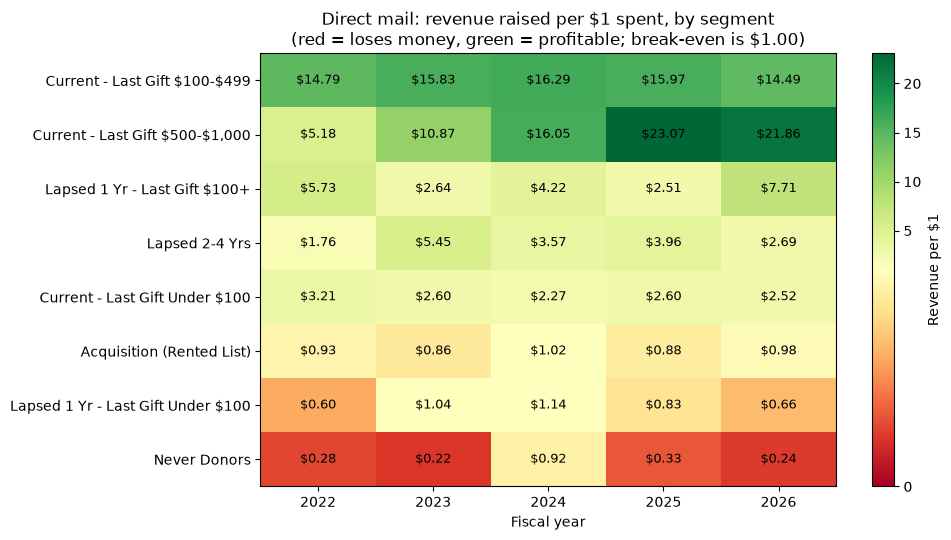

In [15]:
grid = seg_rank.pivot(index="appeal_segment", columns="fiscal_year",
                      values="revenue_per_dollar")
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]   # best segments on top

fig, ax = plt.subplots(figsize=(10, 5.5))
img = ax.imshow(grid.values, cmap="RdYlGn", aspect="auto",
                norm=TwoSlopeNorm(vmin=0, vcenter=1, vmax=grid.values.max()))

ax.set_xticks(range(len(grid.columns)), labels=grid.columns)
ax.set_yticks(range(len(grid.index)),
              labels=[label.replace("$", r"\$") for label in grid.index])

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"${grid.values[i, j]:.2f}", ha="center", va="center", fontsize=9)

ax.set_xlabel("Fiscal year")
ax.set_title("Direct mail: revenue raised per $1 spent, by segment\n"
             "(red = loses money, green = profitable; break-even is $1.00)")
fig.colorbar(img, ax=ax, label="Revenue per $1")
plt.tight_layout()
fig.savefig("images/segment_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

The two Current Donors segments with last gifts of $100 or more are the strongest every year, raising about $5–$23 for every $1 spent ($14–$16 for $100–$499, and $5–$23 for $500–$1,000). At the other end, Never Donors raised less than they cost in all five years ($0.22–$0.92 per $1), and Lapsed 1 Yr – Last Gift Under $100 lost money in three of five years ($0.60–$1.14). The acquisition mailing hovers around break-even ($0.86–$1.02), which is expected, since its value comes from future giving. Lapsed 2-4 Yrs is profitable every year ($1.76–$5.45).

**One point worth noting**: the Never Donors mailing loses money in the year it is sent, but the few who respond return at the highest rate of any new-donor group (48% in Part 3). Like acquisition, it may be worth judging on long-term value rather than first-year return.

Part 3 follows new donors from every channel to see how they first gave and which ones make a second gift. 

## Part 3: Where new donors come from, and which ones give again

Most first-time donors never make a second gift, so this section follows donors whose first-ever gift came in FY22 or later: which channel brought them in, how large their first gift was, and whether they gave again.

In [16]:
new_by_channel = con.sql("""
    WITH first_gifts AS (
        SELECT
            g.donor_id,
            g.fiscal_year,
            g.amount,
            g.gift_type,
            g.segment_group,
            a.channel,
            ROW_NUMBER() OVER (PARTITION BY g.donor_id
                               ORDER BY g.gift_date, g.gift_id) AS gift_order
        FROM gifts g
        JOIN appeals a ON a.appeal_id = g.appeal_id
        JOIN donors d  ON d.donor_id  = g.donor_id
        WHERE d.first_gift_fy >= 2022
    )
    SELECT
        fiscal_year,
        CASE WHEN channel = 'Direct Mail' AND segment_group = 'Acquisition (Rented List)'
                 THEN 'Mail: acquisition'
             WHEN channel = 'Direct Mail' THEN 'Mail: never donors'
             WHEN channel = 'Unsolicited' AND gift_type <> 'Standard'
                 THEN 'Unsolicited: tribute or fundraiser'
             WHEN channel = 'Unsolicited' THEN 'Unsolicited: standard'
             ELSE channel END              AS channel_group,
        COUNT(*)                           AS new_donors,
        ROUND(AVG(amount), 2)              AS avg_first_gift
    FROM first_gifts
    WHERE gift_order = 1
    GROUP BY fiscal_year,
             CASE WHEN channel = 'Direct Mail' AND segment_group = 'Acquisition (Rented List)'
                      THEN 'Mail: acquisition'
                  WHEN channel = 'Direct Mail' THEN 'Mail: never donors'
                  WHEN channel = 'Unsolicited' AND gift_type <> 'Standard'
                      THEN 'Unsolicited: tribute or fundraiser'
                  WHEN channel = 'Unsolicited' THEN 'Unsolicited: standard'
                  ELSE channel END
    ORDER BY fiscal_year, new_donors DESC
""").df()

new_by_channel

,fiscal_year,channel_group,new_donors,avg_first_gift
0,2022,Mail: acquisition,193,82.60
1,2022,Unsolicited: tribute or fundraiser,101,64.13
2,2022,Unsolicited: standard,100,75.81
3,2022,Social Media,33,49.54
4,2022,Mail: never donors,12,79.24
5,2022,Email,5,68.21
6,2023,Mail: acquisition,181,81.35
7,2023,Unsolicited: tribute or fundraiser,111,66.35
8,2023,Unsolicited: standard,103,68.12
9,2023,Social Media,49,43.76


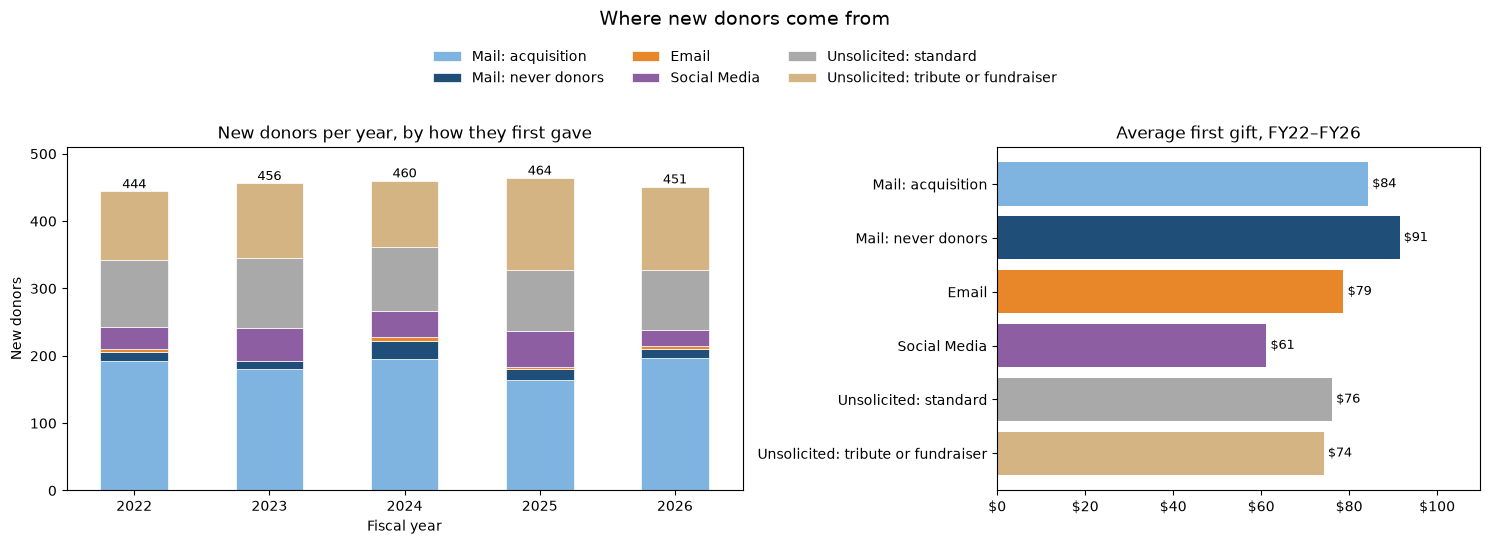

In [17]:
# Colors for each way a new donor came in (matches the channel colors used above where they overlap)
new_donor_colors = {
    "Mail: acquisition":                  "#7fb3e0",   # light blue
    "Mail: never donors":                 "#1f4e79",   # dark blue
    "Email":                              "#e8862a",   # orange
    "Social Media":                       "#8e5ea2",   # purple
    "Unsolicited: standard":              "#a9a9a9",   # gray
    "Unsolicited: tribute or fundraiser": "#d4b483",   # tan
}
order = [c for c in new_donor_colors if c in new_by_channel["channel_group"].unique()]

counts = (new_by_channel
    .pivot(index="fiscal_year", columns="channel_group", values="new_donors")
    .reindex(columns=order)
    .fillna(0))

# Average first gift across all five years, weighted by number of donors
totals = new_by_channel.assign(revenue=new_by_channel["new_donors"] * new_by_channel["avg_first_gift"])
avg_first = (totals.groupby("channel_group")[["revenue", "new_donors"]].sum()
             .assign(avg=lambda x: x["revenue"] / x["new_donors"])["avg"]
             .reindex(order[::-1]))   # same order as the stacked bars, top to bottom

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})

# Left: new donors per year, stacked by channel
counts.plot(kind="bar", stacked=True, ax=axes[0], legend=False,
            color=[new_donor_colors[c] for c in order], edgecolor="white", linewidth=0.5)
for i, total in enumerate(counts.sum(axis=1)):
    axes[0].text(i, total + 5, f"{total:,.0f}", ha="center", fontsize=9)
axes[0].set_title("New donors per year, by how they first gave")
axes[0].set_xlabel("Fiscal year")
axes[0].set_ylabel("New donors")
axes[0].set_ylim(0, counts.sum(axis=1).max() * 1.1)
axes[0].tick_params(axis="x", rotation=0)

# Right: average first gift by channel
bars = axes[1].barh(avg_first.index, avg_first.values,
                    color=[new_donor_colors[c] for c in avg_first.index])
axes[1].bar_label(bars, labels=[f"${v:,.0f}" for v in avg_first.values], padding=3, fontsize=9)
axes[1].set_title("Average first gift, FY22–FY26")
axes[1].set_xlim(0, avg_first.max() * 1.2)
axes[1].xaxis.set_major_formatter(lambda x, pos: f"${x:,.0f}")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 0.93), frameon=False)
fig.suptitle("Where new donors come from", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.86])
fig.savefig("images/new_donor_sources.png", dpi=150, bbox_inches="tight")
plt.show()

The acquisition mailing brings in the most new donors each year (164–197), followed by unsolicited gifts (193–227 a year combined), which split between standard gifts and tribute or personal fundraiser gifts. Social media adds a smaller but steady group (24–54 a year), while the Never Donors mailing and email add only a handful. First gifts are modest across the board, averaging about $61 (social media) to $91 (Never Donors mailing).

In [18]:
second_gift = con.sql("""
    WITH numbered AS (
        SELECT
            g.donor_id,
            g.gift_date,
            g.fiscal_year,
            g.amount,
            g.gift_type,
            g.segment_group,
            a.channel,
            ROW_NUMBER() OVER (PARTITION BY g.donor_id
                               ORDER BY g.gift_date, g.gift_id) AS gift_order
        FROM gifts g
        JOIN appeals a ON a.appeal_id = g.appeal_id
        JOIN donors d  ON d.donor_id  = g.donor_id
        WHERE d.first_gift_fy >= 2022
    ),
    first_gift AS (
        SELECT donor_id, fiscal_year AS first_fy, amount AS first_amount,
            CASE WHEN channel = 'Direct Mail' AND segment_group = 'Acquisition (Rented List)'
                     THEN 'Mail: acquisition'
                 WHEN channel = 'Direct Mail' THEN 'Mail: never donors'
                 WHEN channel = 'Unsolicited' AND gift_type <> 'Standard'
                     THEN 'Unsolicited: tribute or fundraiser'
                 WHEN channel = 'Unsolicited' THEN 'Unsolicited: standard'
                 ELSE channel END AS channel_group
        FROM numbered
        WHERE gift_order = 1
          AND fiscal_year <= 2025          -- FY26 donors haven't had a full next year yet
    ),
    second_gift AS (
        SELECT donor_id, fiscal_year AS second_fy
        FROM numbered
        WHERE gift_order = 2
    )
    SELECT
        f.channel_group,
        COUNT(*)                                                    AS new_donors,
        SUM(CASE WHEN s.second_fy <= f.first_fy + 1
                 THEN 1 ELSE 0 END)                                 AS gave_again,
        ROUND(100.0 * SUM(CASE WHEN s.second_fy <= f.first_fy + 1
                               THEN 1 ELSE 0 END) / COUNT(*), 1)    AS pct_second_gift,
        ROUND(AVG(f.first_amount), 2)                               AS avg_first_gift
    FROM first_gift f
    LEFT JOIN second_gift s ON s.donor_id = f.donor_id
    GROUP BY f.channel_group
    ORDER BY pct_second_gift DESC
""").df()

second_gift

,channel_group,new_donors,gave_again,pct_second_gift,avg_first_gift
0,Mail: never donors,65,31.0,47.7,94.84
1,Mail: acquisition,734,171.0,23.3,85.52
2,Unsolicited: standard,388,90.0,23.2,75.46
3,Social Media,175,38.0,21.7,60.29
4,Unsolicited: tribute or fundraiser,447,17.0,3.8,72.55
5,Email,15,0.0,0.0,92.71


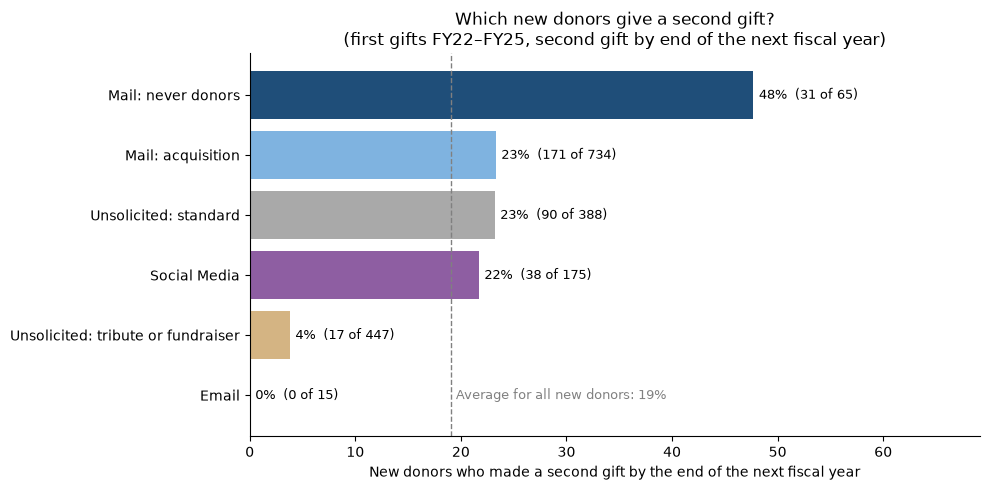

In [19]:
plot_data = second_gift.sort_values("pct_second_gift")   # highest at top
overall = 100 * second_gift["gave_again"].sum() / second_gift["new_donors"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_data["channel_group"], plot_data["pct_second_gift"],
               color=[new_donor_colors[c] for c in plot_data["channel_group"]])
ax.bar_label(bars,
             labels=[f"{p:.0f}%  ({int(s):,} of {n:,})" for p, s, n in
                     zip(plot_data["pct_second_gift"], plot_data["gave_again"],
                         plot_data["new_donors"])],
             padding=4, fontsize=9)
ax.axvline(overall, color="gray", linestyle="--", linewidth=1)

ax.set_xlim(0, plot_data["pct_second_gift"].max() * 1.45)
ax.text(overall + 0.5, 0, f"Average for all new donors: {overall:.0f}%",
          color="gray", fontsize=9, va="center")
ax.set_xlabel("New donors who made a second gift by the end of the next fiscal year")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("Which new donors give a second gift?\n"
               "(first gifts FY22–FY25, second gift by end of the next fiscal year)",
               fontsize=12)
plt.tight_layout()
fig.savefig("images/second_gift_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this chart:** Each bar is a group of new donors, grouped by how their first gift came in. The length of the bar is the share of that group who made a second gift, and the label shows the count behind it. 
The dashed line is the average for all new donors combined: 19%, or 347 of 1,824. Bars that reach past the line did better than average, and bars that stop short of it did worse.

**Every group is measured the same way:** a donor counts as giving again if their second gift arrived by the end of the fiscal year after their first gift. For example, a donor whose first gift came in October 2022 (FY23) counts only if they gave again by June 30, 2024 (the end of FY24). First gifts from FY26 are left out because a full fiscal year has not passed since their gift was made. 

**What it shows:** Tribute and personal fundraiser donors make up about a quarter of all new donors (447), but only 4% of them gave again. That fits what is known about tribute giving: these donors gave because of someone they know rather than a connection to the organization, and personal fundraiser platforms often pass along little contact information. Leaving them out, 24% of new donors gave again.

The acquisition mailing, standard unsolicited gifts, and social media all land at 22–23%. The acquisition mailing and standard unsolicited gifts (via online and mail) bring in most new donors (1,122 out of 1,824 total). The Never Donors mailing stands out at 48% (31 of 65), though the group is small. Email brought in too few new donors to judge (0 of 15).



In [20]:
time_to_second = con.sql("""
    WITH numbered AS (
        SELECT
            g.donor_id,
            g.gift_date,
            g.fiscal_year,
            g.gift_type,
            g.segment_group,
            a.channel,
            ROW_NUMBER() OVER (PARTITION BY g.donor_id
                               ORDER BY g.gift_date, g.gift_id) AS gift_order
        FROM gifts g
        JOIN appeals a ON a.appeal_id = g.appeal_id
        JOIN donors d  ON d.donor_id  = g.donor_id
        WHERE d.first_gift_fy >= 2022
    ),
    first_gift AS (
        SELECT donor_id, gift_date AS first_date,
            CASE WHEN channel = 'Direct Mail' AND segment_group = 'Acquisition (Rented List)'
                     THEN 'Mail: acquisition'
                 WHEN channel = 'Direct Mail' THEN 'Mail: never donors'
                 WHEN channel = 'Unsolicited' AND gift_type <> 'Standard'
                     THEN 'Unsolicited: tribute or fundraiser'
                 WHEN channel = 'Unsolicited' THEN 'Unsolicited: standard'
                 ELSE channel END AS channel_group
        FROM numbered
        WHERE gift_order = 1
          AND fiscal_year <= 2024          -- everyone has at least 24 months of follow-up
    ),
    second_gift AS (
        SELECT donor_id, gift_date AS second_date
        FROM numbered
        WHERE gift_order = 2
    ),
    gaps AS (
        SELECT
            f.channel_group,
            -- MySQL equivalent: DATEDIFF(s.second_date, f.first_date)
            DATE_DIFF('day', f.first_date, s.second_date) AS days_to_second
        FROM first_gift f
        LEFT JOIN second_gift s ON s.donor_id = f.donor_id
    )
    SELECT
        channel_group,
        COUNT(*) AS new_donors,
        ROUND(100.0 * SUM(CASE WHEN days_to_second <= 91  THEN 1 ELSE 0 END) / COUNT(*), 1) AS within_3_months,
        ROUND(100.0 * SUM(CASE WHEN days_to_second <= 182 THEN 1 ELSE 0 END) / COUNT(*), 1) AS within_6_months,
        ROUND(100.0 * SUM(CASE WHEN days_to_second <= 365 THEN 1 ELSE 0 END) / COUNT(*), 1) AS within_12_months,
        ROUND(100.0 * SUM(CASE WHEN days_to_second <= 548 THEN 1 ELSE 0 END) / COUNT(*), 1) AS within_18_months,
        ROUND(100.0 * SUM(CASE WHEN days_to_second <= 730 THEN 1 ELSE 0 END) / COUNT(*), 1) AS within_24_months
    FROM gaps
    GROUP BY channel_group
    ORDER BY within_24_months DESC
""").df()

time_to_second

,channel_group,new_donors,within_3_months,within_6_months,within_12_months,within_18_months,within_24_months
0,Mail: never donors,49,0.0,12.2,30.6,51.0,53.1
1,Social Media,121,0.0,3.3,11.6,19.8,24.8
2,Unsolicited: standard,298,0.0,1.3,9.4,20.8,24.2
3,Mail: acquisition,570,0.7,0.9,1.8,15.8,22.8
4,Email,12,0.0,0.0,0.0,0.0,8.3
5,Unsolicited: tribute or fundraiser,310,0.0,0.0,1.6,3.5,4.5


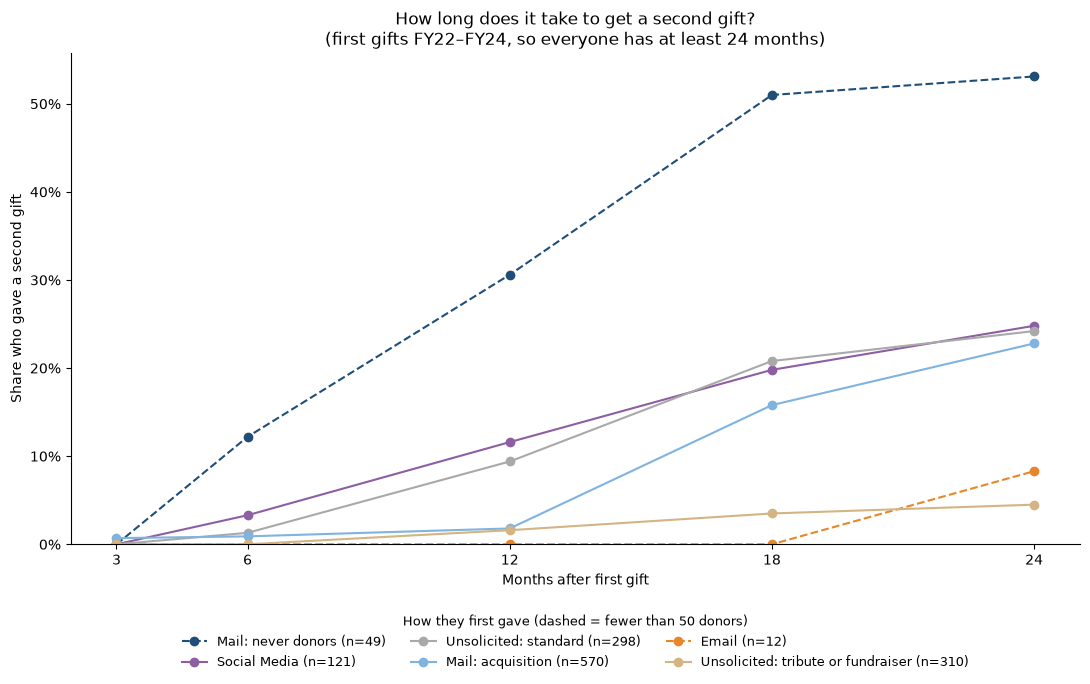

In [21]:
months = [3, 6, 12, 18, 24]
columns = ["within_3_months", "within_6_months", "within_12_months",
           "within_18_months", "within_24_months"]

fig, ax = plt.subplots(figsize=(11, 7))   # taller
for _, row in time_to_second.iterrows():
    small = row["new_donors"] < 50
    ax.plot(months, row[columns].values, marker="o",
            linestyle="--" if small else "-",          # dashed = small group
            color=new_donor_colors[row["channel_group"]],
            label=f"{row['channel_group']} (n={row['new_donors']:,})")

ax.set_xticks(months)
ax.set_xlabel("Months after first gift")
ax.set_ylabel("Share who gave a second gift")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0f}%")
ax.set_ylim(bottom=0)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

# Legend below the chart, in three columns
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.12),
          title="How they first gave (dashed = fewer than 50 donors)", title_fontsize=9)

ax.set_title("How long does it take to get a second gift?\n"
             "(first gifts FY22–FY24, so everyone has at least 24 months)")
plt.tight_layout()
fig.savefig("images/time_to_second_gift.png", dpi=150, bbox_inches="tight")
plt.show()

The chart above measures how long it takes to give a second gift. To compare everyone on equal time, it only includes first gifts from FY22–FY24, so every donor has had at least 24 months to give again.

Almost no one gives again quickly: within 6 months, only 0–3% of most groups had made a second gift (12% for the Never Donors mailing). By 12 months, the share is still low for most groups (9–12% for standard unsolicited and social media donors), and acquisition donors barely move at all (2%). The biggest jump comes between 12 and 18 months, when acquisition donors go from 2% to 16% before reaching 23% by 24 months. Email brought in too few new donors with only 1 out of 12 making a second gift after 24 months. 

This lines up with the appeal calendar. The acquisition mailing goes out in September, so most acquisition donors make their first gift in the fall, and their second gift usually comes with the following year's fall and year-end appeals, more than a year later. That leaves a long gap after the first gift where little happens, which is where a stewardship plan (a prompt thank you, a welcome mailing, an impact update) and an earlier, well-timed second ask could change this. 

### Acquisition: does it pay off once donors give again?

Compares the cost of each year's acquisition mailing (within the 5 years of this dataset) with how much its new donors have given since to see whether their gifts cover the cost.

In [22]:
acq_payback = con.sql("""
    WITH cohort AS (
        SELECT donor_id, first_gift_fy AS cohort_fy
        FROM donors
        WHERE acquisition_source = 'Acquisition Mailing'
          AND first_gift_fy >= 2022
    ),
    acq_cost AS (
        SELECT fiscal_year, total_cost
        FROM appeals
        WHERE appeal_id LIKE '%-DM-ACQ'
    ),
    cohort_revenue AS (
        SELECT
            c.cohort_fy,
            COUNT(DISTINCT c.donor_id) AS new_donors,
            SUM(CASE WHEN g.fiscal_year = c.cohort_fy THEN g.amount ELSE 0 END) AS first_year_revenue,
            SUM(g.amount) AS revenue_to_date
        FROM cohort c
        JOIN gifts g ON g.donor_id = c.donor_id
        GROUP BY c.cohort_fy
    )
    SELECT
        r.cohort_fy,
        r.new_donors,
        ROUND(a.total_cost)                         AS acquisition_cost,
        ROUND(a.total_cost / r.new_donors, 2)       AS cost_per_new_donor,
        ROUND(r.first_year_revenue)                 AS first_year_revenue,
        ROUND(r.revenue_to_date)                    AS revenue_to_date,
        ROUND(r.revenue_to_date - a.total_cost)     AS net_to_date,
        ROUND(r.revenue_to_date / a.total_cost, 2)  AS revenue_per_dollar_to_date,
        2026 - r.cohort_fy                          AS years_of_follow_up
    FROM cohort_revenue r
    JOIN acq_cost a ON a.fiscal_year = r.cohort_fy
    ORDER BY r.cohort_fy
""").df()

acq_payback

,cohort_fy,new_donors,acquisition_cost,cost_per_new_donor,first_year_revenue,revenue_to_date,net_to_date,revenue_per_dollar_to_date,years_of_follow_up
0,2022,193,17219.0,89.22,15943.0,31822.0,14602.0,1.85,4
1,2023,181,17177.0,94.90,15049.0,29936.0,12758.0,1.74,3
2,2024,196,17702.0,90.32,18344.0,27817.0,10115.0,1.57,2
3,2025,164,15852.0,96.66,13962.0,18459.0,2606.0,1.16,1
4,2026,197,15994.0,81.19,15938.0,15938.0,-56.0,1.00,0


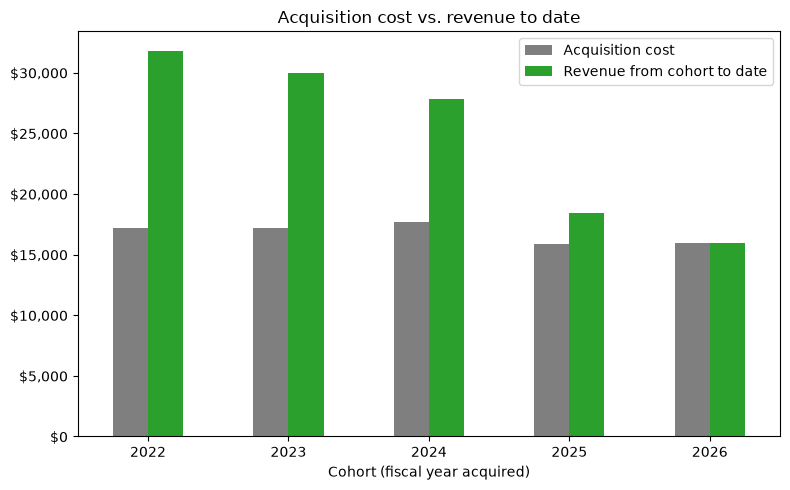

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
(acq_payback
    .set_index("cohort_fy")[["acquisition_cost", "revenue_to_date"]]
    .plot(kind="bar", ax=ax, color=["tab:gray", "tab:green"]))
ax.set_title("Acquisition cost vs. revenue to date")
ax.set_xlabel("Cohort (fiscal year acquired)")
ax.tick_params(axis="x", rotation=0)
ax.yaxis.set_major_formatter(lambda x, pos: f"${x:,.0f}")
ax.legend(["Acquisition cost", "Revenue from cohort to date"])
plt.tight_layout()
fig.savefig("images/acquisition_payback.png", dpi=150, bbox_inches="tight")
plt.show()

This chart compares the cost of each year's acquisition mailing with the gross revenue the donors it brought in have contributed through FY26. Every cohort from FY22–FY25 has already given more than its mailing cost, from $1.16 per $1 spent for FY25 (one year of follow-up) to $1.85 for FY22 (four years). The FY26 cohort is essentially at break-even after its first year ($56 short). Older cohorts have had more years to give, so their totals are naturally higher.

In four of the five years, first-year gifts alone did not cover the cost of the mailing (FY24 was the exception by a small amount), so the cohorts have paid back mostly through second and later gifts. That makes the second gift what turns acquisition from a cost into an investment.

## Conclusion and next steps

**Who gives:** Unsurprisingly, annual giving revenue mostly comes from donors who are already giving. House file mail raised 68% of solicited revenue, and current donors responded to mail far more often than lapsed or never donors. Personal outreach to the top donors is very effective, but reaches the smallest audience. Email and social media raise smaller amounts, and social media brings in a steady group of new donors.

**What it costs:** Direct mail raises the most money, and appeals to the house file are among the most efficient asks in the program (about $0.19–$0.22 to raise $1). Email, social media, and personal outreach return more per dollar but raise far less. The acquisition mailing roughly breaks even in its first year (and improves by the second), which lowers direct mail's overall return.

**The second gift:** New donors arrive through many channels, mostly the acquisition mailing and unsolicited gifts, but only 19% give again by the end of the following year, and acquisition only pays for itself through those second and later gifts. Most second gifts come 12–18 months after the first, so the first year after a donor’s first gift is the clearest opportunity: a stewardship plan for new donors (such as a prompt thank you letter, a welcome mailing, and an update on the impact of their gift) and a well-timed second ask. It is also important to capture contact information whenever possible, especially for donors who give via a third party, since those platforms often provide limited contact information, and mail only works with a valid address. Tribute and personal fundraiser donors return at a much lower rate, so a smaller, less expensive approach makes more sense for them than the full stewardship plan.

**Next step:** This analysis shows which groups of new donors are more likely to give again, but not which individual donors. Next, I will build a machine learning model that predicts each donor's likelihood of giving in the following year, using giving history, recency, gift size, event attendance, and contact information. That would allow the organization to focus mail and stewardship on the donors most likely to give, and reach less likely donors through lower cost channels like email.
